# **Asphalt Pavement Condition Classification**

In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Conv1D, Dense, Flatten, Dropout, MaxPooling1D, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import keras_tuner as kt
from larq.layers import QuantConv1D, QuantDense
from larq.models import summary
import larq_compute_engine as lce
import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
import numpy as np
import scipy.io
import joblib
import numpy as np
import pandas as pd
from tabulate import tabulate

2025-03-28 18:41:29.056546: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-28 18:41:29.095113: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-03-28 18:41:29.095145: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-28 18:41:29.095175: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-28 18:41:29.101560: I tensorflow/core/platform/cpu_feature_g

In [2]:
# Check if GPU is Available
print("Num GPUs Available: ", tf.config.list_physical_devices('GPU'))
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    # Print information about each GPU
    for gpu in gpus:
        print("GPU:", gpu.name)
else:
    print("No GPU devices found.")

Num GPUs Available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU: /physical_device:GPU:0


2025-03-28 18:41:31.368090: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-03-28 18:41:31.372870: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-03-28 18:41:31.373045: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysf

## Dataset Preparation

In [3]:
def load_ts_file(filepath):
    """Load time series data from .ts file"""
    with open(filepath, 'r') as file:
        lines = file.readlines()
        
    # Skip header lines
    data_start_idx = 0
    for i, line in enumerate(lines):
        if line.strip() == '@data':
            data_start_idx = i + 1
            break
    
    X = []
    y = []
    
    # Parse data lines
    for line in lines[data_start_idx:]:
        try:
            # Split line into data and label
            parts = line.strip().split(',')
            
            # Convert time series data to float
            values = [float(val) for val in parts[:-1]]
            X.append(np.array(values, dtype=np.float32))
            
            # Parse label (regular = 0, deteriorated = 1)
            # Format is "number:label", we only want the label part
            label_str = parts[-1].strip().split(':')[-1].lower()
            if label_str == 'regular':
                label = 0
            elif label_str == 'deteriorated':
                label = 1
            else:
                print(f"Unknown label found: {label_str}")
                continue
                
            y.append(label)
            
        except Exception as e:
            print(f"Error parsing line: {line}")
            print(f"Error: {e}")
            continue
    
    X = np.array(X)
    y = np.array(y, dtype=np.int32)
    
    print(f"File {filepath}:")
    print(f"Number of samples: {len(X)}")
    print(f"Unique labels: {np.unique(y)}")
    print(f"Label distribution: {np.bincount(y)}\n")
    
    return X, y

In [4]:
class AsphaltDataLoader:
    def __init__(self, data_dir='AsphaltRegularity', seed=42):
        self.data_dir = data_dir
        self.seed = seed
        self.scaler = StandardScaler()
        
    def load_dataset(self, batch_size=32, val_split=0.15):
        # Load training data from _eq file
        train_file = os.path.join(self.data_dir, 'AsphaltRegularity_eq_TRAIN.ts')
        X_train_raw, y_train = load_ts_file(train_file)
        
        # Load test data from _eq file
        test_file = os.path.join(self.data_dir, 'AsphaltRegularity_eq_TEST.ts')
        X_test_raw, y_test = load_ts_file(test_file)
        
        # Print dataset statistics
        print("Training samples:", len(X_train_raw))
        print("Test samples:", len(X_test_raw))
        print("Unique classes in training:", np.unique(y_train))
        print("Class distribution in training:", np.bincount(y_train))
        
        # Scale the features
        X_train = self.scaler.fit_transform(X_train_raw)
        X_test = self.scaler.transform(X_test_raw)
        
        # Split training data into train and validation
        train_size = int(len(X_train) * (1 - val_split))
        
        # Shuffle indices
        indices = np.arange(len(X_train))
        np.random.seed(self.seed)
        np.random.shuffle(indices)
        
        # Create train and validation sets
        X_train_final = X_train[indices[:train_size]]
        y_train_final = y_train[indices[:train_size]]
        X_val = X_train[indices[train_size:]]
        y_val = y_train[indices[train_size:]]
        
        # Reshape data to add channel dimension
        X_train_final = X_train_final.reshape(-1, X_train_final.shape[1], 1)
        X_val = X_val.reshape(-1, X_val.shape[1], 1)
        X_test = X_test.reshape(-1, X_test.shape[1], 1)
        
        # Create TensorFlow datasets
        train_ds = tf.data.Dataset.from_tensor_slices((X_train_final, y_train_final))\
            .shuffle(buffer_size=10000)\
            .batch(batch_size)\
            .prefetch(tf.data.AUTOTUNE)
            
        val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))\
            .batch(batch_size)\
            .prefetch(tf.data.AUTOTUNE)
            
        test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))\
            .batch(batch_size)\
            .prefetch(tf.data.AUTOTUNE)
        
        sequence_length = X_train_final.shape[1]
        
        return train_ds, val_ds, test_ds, sequence_length

In [5]:
def load_asphalt_dataset(batch_size=32, seed=42):
    loader = AsphaltDataLoader(seed=seed)
    return loader.load_dataset(batch_size=batch_size)

In [6]:
train_ds, val_ds, test_ds, sequence_length = load_asphalt_dataset(batch_size=32)

File AsphaltRegularity/AsphaltRegularity_eq_TRAIN.ts:
Number of samples: 751
Unique labels: [0 1]
Label distribution: [381 370]

File AsphaltRegularity/AsphaltRegularity_eq_TEST.ts:
Number of samples: 751
Unique labels: [0 1]
Label distribution: [381 370]

Training samples: 751
Test samples: 751
Unique classes in training: [0 1]
Class distribution in training: [381 370]


2025-03-28 18:41:33.586388: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-03-28 18:41:33.586581: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-03-28 18:41:33.586699: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysf

In [7]:
for x, y in train_ds.take(1):
    print("\nDataset shapes:")
    print("Input shape:", x.shape)
    print("Label shape:", y.shape)
    print("Unique classes:", len(tf.unique(y)[0]))
    print("Sequence length:", sequence_length)


Dataset shapes:
Input shape: (32, 4200, 1)
Label shape: (32,)
Unique classes: 2
Sequence length: 4200


## NN Evaluation Methods

In [27]:
def evaluate_NN_models(model_list, test_ds, bin_class=False):
    loss, accuracy, y_pred, precision, recall, f1_score, support, confusion_matrix_list = [], [], [], [], [], [], [], []
    
    # Get all labels from the dataset
    y_test = np.concatenate([y for x, y in test_ds], axis=0)
    
    for model in model_list:
        loss_value, accuracy_value = model.evaluate(test_ds, verbose=0)
        loss.append(loss_value)
        accuracy.append(accuracy_value)
        
        if bin_class:
            y_pred_value = (model.predict(test_ds) > 0.5).astype(int)
        else:
            y_pred_value = np.argmax(np.vstack(model.predict(test_ds)), axis=1)
            
        y_pred.append(y_pred_value)
        y_test_classes = y_test
        
        precision_value, recall_value, f1_score_value, support_value = precision_recall_fscore_support(
            y_test_classes, 
            y_pred_value, 
            average='binary' if bin_class else 'weighted',
            zero_division=0
        )
        
        precision.append(precision_value)
        recall.append(recall_value)
        f1_score.append(f1_score_value)
        support.append(support_value)
        
        confusion_matrix_value = confusion_matrix(y_test_classes, y_pred_value)
        confusion_matrix_list.append(confusion_matrix_value)
        
    return [accuracy, precision, recall, f1_score], confusion_matrix_list, y_pred

In [ ]:
for x, y in train_ds.take(1):
    print("\nDataset shapes:")
    print("Input shape:", x.shape)
    print("Label shape:", y.shape)
    print("Unique classes:", len(tf.unique(y)[0]))
    print("Sequence length:", sequence_length)

Input shape: (32, 4200, 1)
Label shape: (32,)
Number of classes: 1
Sequence length: 4200


In [9]:
def print_table(data,headers):
    table_data = list(zip(*data))
    table = tabulate(table_data, headers=headers, tablefmt='grid')
    print(table)

In [10]:
def plot_confusion_matrix(ax, conf_matrix, title, cmap):
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax)
    ax.set_title(title)

In [11]:
def draw_confusion_matrix(matrix,name):
    colormap=["Blues","Greens","Oranges"]
    fig, axes = plt.subplots(1, 1, figsize=(15, 5))
    for i in range(len(matrix)):
        plot_confusion_matrix(axes, matrix[i], "Confusion Matrix  ", colormap[i])
    plt.tight_layout()

## Hyperparameters Optimization

In [12]:
class BinaryNetHyperModel(kt.HyperModel):
    def __init__(self, input_shape, num_classes):
        self.input_shape = input_shape
        self.num_classes = num_classes

    def build(self, hp):
        kwargs = dict(input_quantizer="ste_sign",
                     kernel_quantizer="ste_sign",
                     kernel_constraint="weight_clip")

        model = Sequential()
        
        # Tune the first Conv1D layer
        filters_conv1 = hp.Int('conv1_filters', min_value=16, max_value=64, step=16)
        model.add(Conv1D(filters=filters_conv1, kernel_size=3, activation='relu', 
                        input_shape=self.input_shape))
        model.add(MaxPooling1D(pool_size=2))
        model.add(BatchNormalization(scale=False))

        # Tune the first QuantConv1D layer
        filters_qconv1 = hp.Int('qconv1_filters', min_value=4, max_value=16, step=4)
        model.add(QuantConv1D(filters_qconv1, kernel_size=3,
                             kernel_quantizer="ste_sign",
                             kernel_constraint="weight_clip",
                             use_bias=False))
        model.add(MaxPooling1D(pool_size=2))
        model.add(BatchNormalization(scale=False))
        model.add(Dropout(rate=hp.Float('dropout1', min_value=0.2, max_value=0.5)))

        # Tune the second QuantConv1D layer
        filters_qconv2 = hp.Int('qconv2_filters', min_value=4, max_value=16, step=4)
        model.add(QuantConv1D(filters_qconv2, kernel_size=3, use_bias=False, **kwargs))
        model.add(MaxPooling1D(pool_size=2))
        model.add(BatchNormalization(scale=False))
        model.add(Dropout(rate=hp.Float('dropout2', min_value=0.2, max_value=0.5)))

        model.add(Flatten())

        # Tune the QuantDense layer
        units_qdense = hp.Int('qdense_units', min_value=4, max_value=16, step=4)
        model.add(QuantDense(units_qdense, use_bias=False, **kwargs))
        model.add(BatchNormalization(scale=False))
        model.add(Dense(1, activation='sigmoid'))

        # Tune learning rate
        learning_rate = hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log')
        model.compile(
            optimizer=Adam(learning_rate=learning_rate),
            loss='binary_crossentropy',
            metrics=['accuracy']
        )
        return model

In [13]:
# Initialize the hypermodel
hypermodel = BinaryNetHyperModel(input_shape=(sequence_length, 1), num_classes=2)

# Create the tuner
tuner = kt.BayesianOptimization(
    hypermodel,
    objective='val_accuracy',
    max_trials=20,
    directory='bayesian_opt',
    project_name='asphalt_tune'
)

# Define early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    verbose=1,
    mode='min',
    restore_best_weights=True
)

# Search for the best hyperparameters
tuner.search(
    train_ds,
    epochs=100,
    batch_size=64,
    validation_data=val_ds,
    callbacks=[early_stopping]
)

# Get the best hyperparameters
best_hps_list = tuner.get_best_hyperparameters(num_trials=3)
best_models_list = tuner.get_best_models(num_models=3)

Trial 20 Complete [00h 00m 21s]
val_accuracy: 0.9646017551422119

Best val_accuracy So Far: 1.0
Total elapsed time: 00h 06m 27s


In [14]:
# Show the top 3 models
print("\nTop 3 Models Performance:")
print("-" * 50)

for idx, hps in enumerate(best_hps_list, 1):
    print(f"\nModel {idx}:")
    print("Hyperparameters:")
    for param, value in hps.values.items():
        print(f"{param}: {value}")
    print(f"Validation Accuracy: {best_models_list[idx-1].evaluate(val_ds, verbose=0)[1]:.3f}")
        
# Let user choose the model
while True:
    try:
        choice = int(input("\nChoose a model (1, 2, or 3): "))
        if 1 <= choice <= 3:
            break
        print("Please enter 1, 2, or 3")
    except ValueError:
        print("Please enter a valid number")

# Use the chosen model
# model = best_models_list[choice - 1]
chosen_hps = best_hps_list[choice - 1]

print(f"\nSelected Model {choice}")
print("Final hyperparameters:")
for param, value in chosen_hps.values.items():
    print(f"{param}: {value}")


Top 3 Models Performance:
--------------------------------------------------

Model 1:
Hyperparameters:
conv1_filters: 32
qconv1_filters: 12
dropout1: 0.4955461905671645
qconv2_filters: 4
dropout2: 0.49074461570829464
qdense_units: 12
learning_rate: 0.0015033701274620817
Validation Accuracy: 1.000

Model 2:
Hyperparameters:
conv1_filters: 48
qconv1_filters: 8
dropout1: 0.3001894440489634
qconv2_filters: 8
dropout2: 0.4834445604255
qdense_units: 8
learning_rate: 0.004687978980564898
Validation Accuracy: 1.000

Model 3:
Hyperparameters:
conv1_filters: 16
qconv1_filters: 8
dropout1: 0.263578792161519
qconv2_filters: 8
dropout2: 0.3247553502189683
qdense_units: 8
learning_rate: 0.0026619800162710925
Validation Accuracy: 1.000

Selected Model 1
Final hyperparameters:
conv1_filters: 32
qconv1_filters: 12
dropout1: 0.4955461905671645
qconv2_filters: 4
dropout2: 0.49074461570829464
qdense_units: 12
learning_rate: 0.0015033701274620817


## Build BNN

In [15]:
# All quantized layers except the first will use the same options
kwargs = dict(input_quantizer="ste_sign",
            kernel_quantizer="ste_sign",
            kernel_constraint="weight_clip")

model = Sequential()
# First Conv1D layer with tuned filters
model.add(Conv1D(filters=chosen_hps.get('conv1_filters'), kernel_size=3, activation='relu', 
                 input_shape=(sequence_length,1)))
model.add(MaxPooling1D(pool_size=2))
model.add(BatchNormalization(scale=False))

# First QuantConv1D layer with tuned filters
model.add(QuantConv1D(chosen_hps.get('qconv1_filters'), kernel_size=3,
                      kernel_quantizer="ste_sign",
                      kernel_constraint="weight_clip",
                      use_bias=False))
model.add(MaxPooling1D(pool_size=2))
model.add(BatchNormalization(scale=False))
model.add(Dropout(rate=chosen_hps.get('dropout1')))

# Second QuantConv1D layer with tuned filters
model.add(QuantConv1D(chosen_hps.get('qconv2_filters'), kernel_size=3, use_bias=False, **kwargs))
model.add(MaxPooling1D(pool_size=2))
model.add(BatchNormalization(scale=False))
model.add(Dropout(rate=chosen_hps.get('dropout2')))

model.add(Flatten())

# QuantDense layer with tuned units
model.add(QuantDense(chosen_hps.get('qdense_units'), use_bias=False, **kwargs))
model.add(BatchNormalization(scale=False))
model.add(Dense(1, activation='sigmoid'))

In [16]:
lr = chosen_hps.get('learning_rate')
epochs = 300
batch_size = 64

In [17]:
model.compile(optimizer=Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])
print(summary(model))

+sequential_1 stats--------------------------------------------------------------------------------------+
| Layer                  Input prec.         Outputs  # 1-bit  # 32-bit  Memory  1-bit MACs  32-bit MACs |
|                              (bit)                      x 1       x 1    (kB)                          |
+--------------------------------------------------------------------------------------------------------+
| conv1d_1                         -  (-1, 4198, 32)        0       128    0.50           0       403008 |
| max_pooling1d_3                  -  (-1, 2099, 32)        0         0       0           0            0 |
| batch_normalization_4            -  (-1, 2099, 32)        0        64    0.25           0            0 |
| quant_conv1d_2                   -  (-1, 2097, 12)     1152         0    0.14           0      2415744 |
| max_pooling1d_4                  -  (-1, 1048, 12)        0         0       0           0            0 |
| batch_normalization_5            - 

### Train

In [18]:
history= model.fit(train_ds, epochs=epochs, batch_size=batch_size, validation_data=val_ds, callbacks=[early_stopping], verbose=1)

Epoch 1/300
20/20 [==============================] - 3s 28ms/step - loss: 0.5314 - accuracy: 0.7524 - val_loss: 1.5193 - val_accuracy: 0.7699
Epoch 2/300
20/20 [==============================] - 0s 12ms/step - loss: 0.2399 - accuracy: 0.9248 - val_loss: 0.1144 - val_accuracy: 0.9735
Epoch 3/300
20/20 [==============================] - 0s 11ms/step - loss: 0.1810 - accuracy: 0.9498 - val_loss: 1.0903 - val_accuracy: 0.8053
Epoch 4/300
20/20 [==============================] - 0s 12ms/step - loss: 0.1500 - accuracy: 0.9514 - val_loss: 1.1769 - val_accuracy: 0.7876
Epoch 5/300
20/20 [==============================] - 0s 13ms/step - loss: 0.1402 - accuracy: 0.9530 - val_loss: 2.3936 - val_accuracy: 0.6549
Epoch 6/300
20/20 [==============================] - 0s 15ms/step - loss: 0.1332 - accuracy: 0.9561 - val_loss: 1.8802 - val_accuracy: 0.6814
Epoch 7/300
20/20 [==============================] - 0s 18ms/step - loss: 0.1202 - accuracy: 0.9624 - val_loss: 2.0882 - val_accuracy: 0.6637
Epoch 

### Evaluate

In [33]:
result_all_models_FC, confusion_matrix_FC, predicitions_FC = evaluate_NN_models([model], test_ds, bin_class=True)

24/24 [==============================] - 0s 3ms/step


In [34]:
headers=['models','accuracy','precision','recall','f1_score']
data_normal_FC=[["model"]]
data_normal_FC.extend(result_all_models_FC)
print_table(data_normal_FC,headers)

+----------+------------+-------------+----------+------------+
| models   |   accuracy |   precision |   recall |   f1_score |
+==========+============+=============+==========+============+
| model    |   0.972037 |    0.965333 | 0.978378 |   0.971812 |
+----------+------------+-------------+----------+------------+


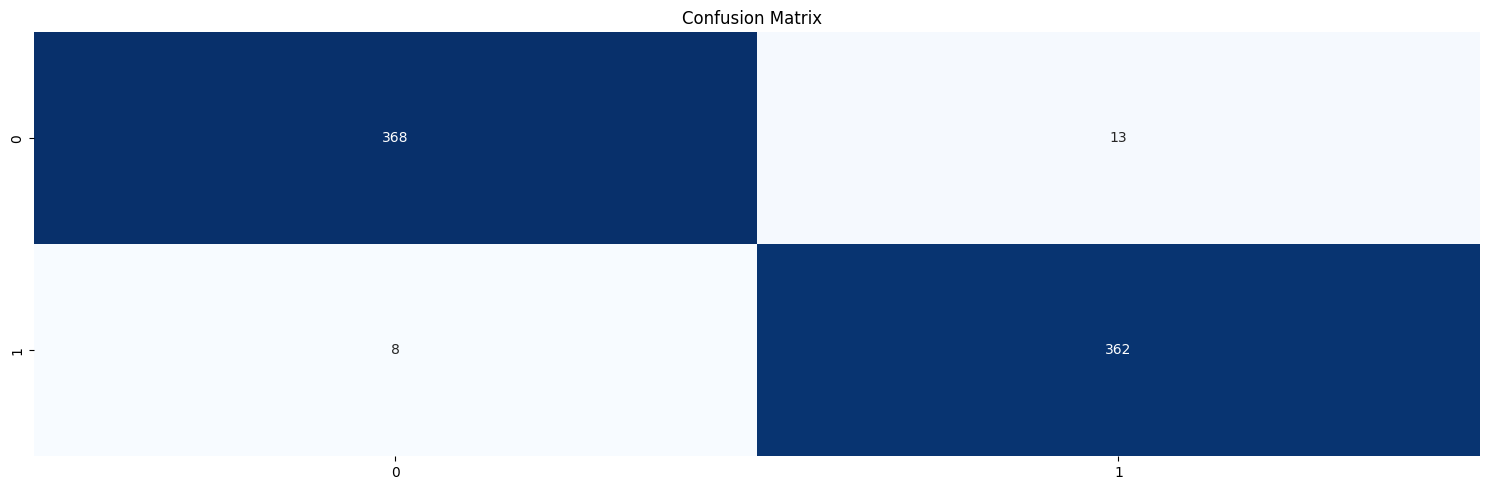

In [35]:
draw_confusion_matrix(confusion_matrix_FC,"Confusion Matrix")

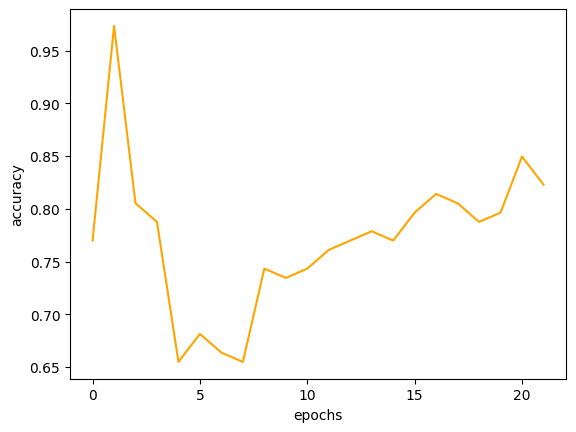

In [36]:
plt.figure()
# plt.plot(history.history['accuracy'], 'g', label='Training Accuracy')
plt.plot(history.history['val_accuracy'], color='orange', label='Validation Accuracy')
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.show()

## Save

In [37]:
# Convert our Keras model to a TFLite flatbuffer file
with open("model.tflite", "wb") as flatbuffer_file:
    flatbuffer_bytes = lce.convert_keras_model(model)
    flatbuffer_file.write(flatbuffer_bytes)

INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3, 32, 12), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x79792c37f490>, 133561349940176), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3, 32, 12), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x79792c37f490>, 133561349940176), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3, 12, 4), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x79792c3b9060>, 133561350114000), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3, 12, 4), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x79792c3b9060>, 133561350114000), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(2092, 12), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x79792c3badd0>, 133561350276000), {}).


...

INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3, 12, 4), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x79792c142350>, 133561350114000), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(2092, 12), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x79792c143400>, 133561350276000), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(2092, 12), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x79792c143400>, 133561350276000), {}).


INFO:tensorflow:Assets written to: /tmp/tmpzqj1dsn2/assets


INFO:tensorflow:Assets written to: /tmp/tmpzqj1dsn2/assets
2025-03-28 18:55:49.003662: I external/org_tensorflow/tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpzqj1dsn2
2025-03-28 18:55:49.006439: I external/org_tensorflow/tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2025-03-28 18:55:49.006467: I external/org_tensorflow/tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: /tmp/tmpzqj1dsn2
2025-03-28 18:55:49.011013: I external/org_tensorflow/tensorflow/cc/saved_model/loader.cc:234] Restoring SavedModel bundle.
2025-03-28 18:55:49.080705: I external/org_tensorflow/tensorflow/cc/saved_model/loader.cc:218] Running initialization op on SavedModel bundle at path: /tmp/tmpzqj1dsn2
2025-03-28 18:55:49.107300: I external/org_tensorflow/tensorflow/cc/saved_model/loader.cc:317] SavedModel load for tags { serve }; Status: success: OK. Took 103643 microseconds.
2025-03-28 18:55:49.197908: I external/or